# Chapitre 9 - Cours 4 : Optimiser le service d'inférence

Les optimisations du service ne touchent pas au modèle : elles décident **quand** et
**où** exécuter chaque requête, avec des ressources fixes (calcul, mémoire) face à une
charge variable. Elles ne doivent donc pas changer les sorties. Ce notebook couvre la
section *Inference Service Optimization* du livre :

- *Batching* : statique, dynamique, continu ;
- *Decoupling prefill and decode* ;
- *Prompt caching* ;
- *Parallelism* : répliques, parallélisme de tenseur, de pipeline, de contexte et de
  séquence.

Pour le batching, nous **mesurons** d'abord le coût d'un pas sur le GPU, puis nous
l'injectons dans une **simulation à événements discrets** d'un serveur : on peut ainsi
comparer les politiques sur des milliers de requêtes en quelques secondes.

**Plan.** 1. Le service comme une file d'attente ; 2. Calibrer un modèle de coût ;
3. Batching statique, dynamique et continu ; 4. Dissocier prefill et decode ; 5. Cache de
prompt ; 6. Parallélisme ; Synthèse.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import KNOWN_CONFIGS, count_params_config, kv_cache_bytes, plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, COLORS,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
POL = {"none": ("sans batching", GRAY), "static": ("statique", ROSE), "dynamic": ("dynamique", AMBER),
       "continuous": ("continu", TEAL)}

## 1. Le service comme une file d'attente (section *Inference Service Optimization*)

Vu de loin, un serveur d'inférence est une **file d'attente** : les requêtes arrivent à des
instants aléatoires, attendent, sont regroupées en lots par un **ordonnanceur**, puis
exécutées sur le GPU. Le livre compare le batching au **bus** : un bus transporte plus de
monde qu'une voiture par personne, mais chacun attend son départ. Toute la question est de
faire partir le bus au bon moment.

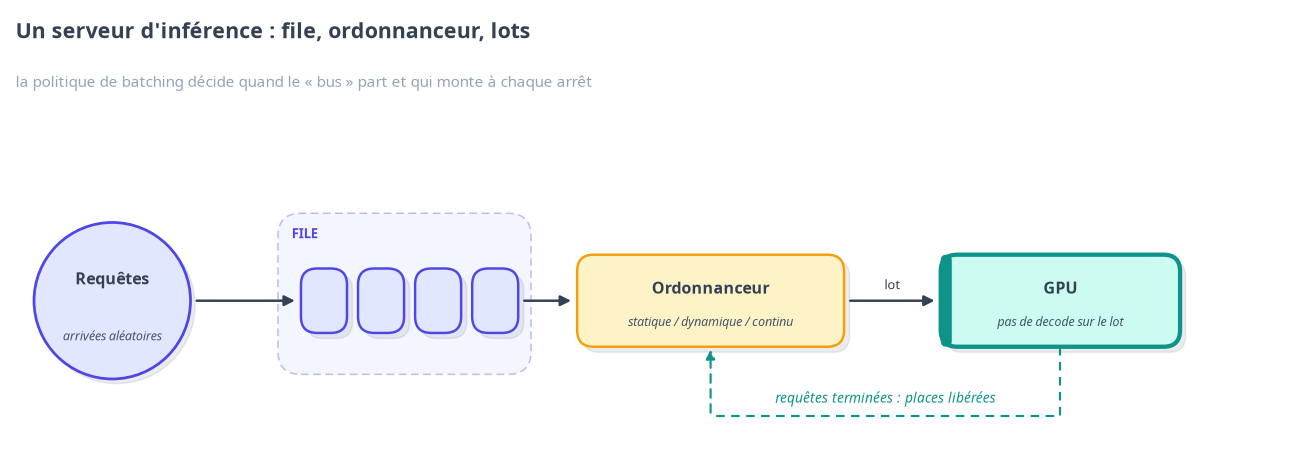

In [2]:
d = Diagram(14, 3.8, title="Un serveur d'inférence : file, ordonnanceur, lots",
            subtitle="la politique de batching décide quand le « bus » part et qui monte à chaque arrêt")
d.box("arr", 1.1, 1.6, "Requêtes", sub="arrivées aléatoires", color=INDIGO, kind="user", w=1.7)
for i in range(4):
    d.box(f"q{i}", 3.4 + i * 0.62, 1.6, "", color=INDIGO, w=0.5, h=0.7)
d.group(2.9, 0.8, 5.65, 2.55, "file", color=INDIGO)
d.box("sch", 7.6, 1.6, "Ordonnanceur", sub="statique / dynamique / continu", color=AMBER, w=2.9, h=1.0)
d.box("gpu", 11.4, 1.6, "GPU", sub="pas de decode sur le lot", color=TEAL, kind="model", w=2.6, h=1.0)
d.arrow("arr", "q0"); d.arrow("q3", "sch"); d.arrow("sch", "gpu", "lot")
d.line([(11.4, 1.1), (11.4, 0.35), (7.6, 0.35), (7.6, 1.1)], color=TEAL, style="dashed", lw=1.4)
d.note(9.5, 0.55, "requêtes terminées : places libérées", color=TEAL, fontsize=9)
d.show()

> **À retenir.** Le service gère des ressources fixes face à une charge variable ; ses
> techniques jouent sur l'ordonnancement, l'emplacement et la réutilisation des calculs,
> sans modifier le modèle.

## 2. Calibrer un modèle de coût (mesures sur le GPU)

Pour simuler un serveur, il faut savoir combien coûte un pas de calcul. Les cours 1 et 2
suggèrent un modèle linéaire :
$$t_{\text{decode}}(b) = a_0 + a_1 b, \qquad t_{\text{prefill}}(n) = p_0 + p_1 n,$$
avec $b$ le nombre de séquences décodées ensemble et $n$ le nombre de tokens préremplis.
On mesure ces durées sur Qwen2.5-0.5B (médianes de répétitions) et on ajuste les
coefficients par moindres carrés.

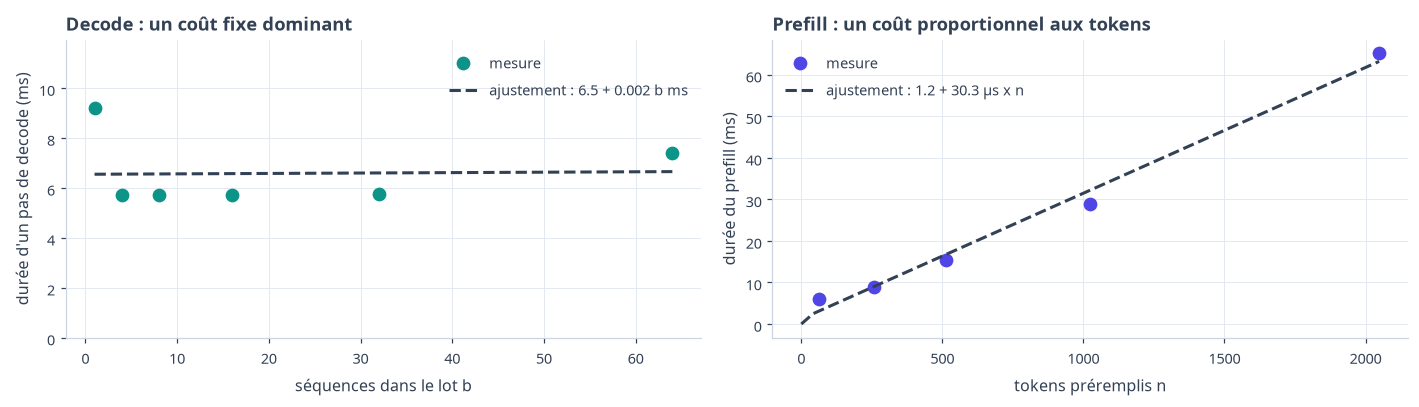

In [3]:
tok, model = inf.retry_oom(llm.load, llm.SMALL)


def calibrate():
    dec = [(b, inf.decode_step_time(model, batch=b, context=256, steps=16)["median"]) for b in [1, 4, 8, 16, 32, 64]]
    pre = [(n, inf.prefill_time(model, n, repeats=5)["median"]) for n in [64, 256, 512, 1024, 2048]]
    return np.array(dec), np.array(pre)


dec, pre = inf.retry_oom(calibrate)
a1, a0 = np.polyfit(dec[:, 0], dec[:, 1], 1)
p1, p0 = np.polyfit(pre[:, 0], pre[:, 1], 1)
cost = inf.StepCost(dec0=max(a0, 1e-3), dec1=max(a1, 1e-6), pre0=max(p0, 1e-3), pre1=max(p1, 1e-7))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.plot(dec[:, 0], dec[:, 1] * 1e3, "o", color=TEAL, ms=8, label="mesure")
bb = np.linspace(1, 64, 50)
ax.plot(bb, [cost.decode(b) * 1e3 for b in bb], color=SLATE, ls="--",
        label=f"ajustement : {cost.dec0 * 1e3:.1f} + {cost.dec1 * 1e3:.3f} b ms")
ax.set_xlabel("séquences dans le lot b"); ax.set_ylabel("durée d'un pas de decode (ms)"); ax.legend()
ax.set_ylim(0, dec[:, 1].max() * 1e3 * 1.3); ax.set_title("Decode : un coût fixe dominant")
ax = axes[1]
ax.plot(pre[:, 0], pre[:, 1] * 1e3, "o", color=INDIGO, ms=8, label="mesure")
nn = np.linspace(0, 2048, 50)
ax.plot(nn, [cost.prefill(n) * 1e3 for n in nn], color=SLATE, ls="--",
        label=f"ajustement : {cost.pre0 * 1e3:.1f} + {cost.pre1 * 1e6:.1f} µs x n")
ax.set_xlabel("tokens préremplis n"); ax.set_ylabel("durée du prefill (ms)"); ax.legend()
ax.set_title("Prefill : un coût proportionnel aux tokens")
plt.tight_layout(); plt.show()

Le modèle linéaire décrit bien les mesures. Le terme fixe du decode $a_0$ (lecture des
poids et surcoût de lancement) domine le terme par séquence $a_1$ de plus d'un ordre de
grandeur : c'est ce rapport qui rend le batching si rentable. Ces coefficients
alimentent toutes les simulations de la suite.

> **À retenir.** Un pas de decode coûte $a_0 + a_1 b$ avec $a_0 \gg a_1$ : servir $b$
> séquences coûte à peine plus qu'en servir une.

## 3. Batching statique, dynamique et continu (section *Batching*)

- **Statique** : le bus attend d'être plein (taille de lot fixe $B$). La première requête
  attend la $B$-ième, aussi tard soit-elle.
- **Dynamique** : le bus part quand il est plein **ou** après une fenêtre de temps fixe
  (par exemple 100 ms) ; la latence est bornée, au prix de lots parfois incomplets.
- **Continu** (*continuous* ou *in-flight batching*, Orca, Yu et al., 2022) : le lot est
  recomposé à **chaque pas** de decode ; une requête terminée sort immédiatement et une
  requête en attente prend sa place. Le bus dépose et prend des passagers à chaque arrêt.

Dans un batching naïf (statique ou dynamique), une réponse de 10 tokens attend la fin d'une
réponse de 1 000 tokens du même lot. Visualisons les trois politiques sur 12 requêtes
(arrivées de Poisson, longueurs de sortie très variables), avec des lots de 4.

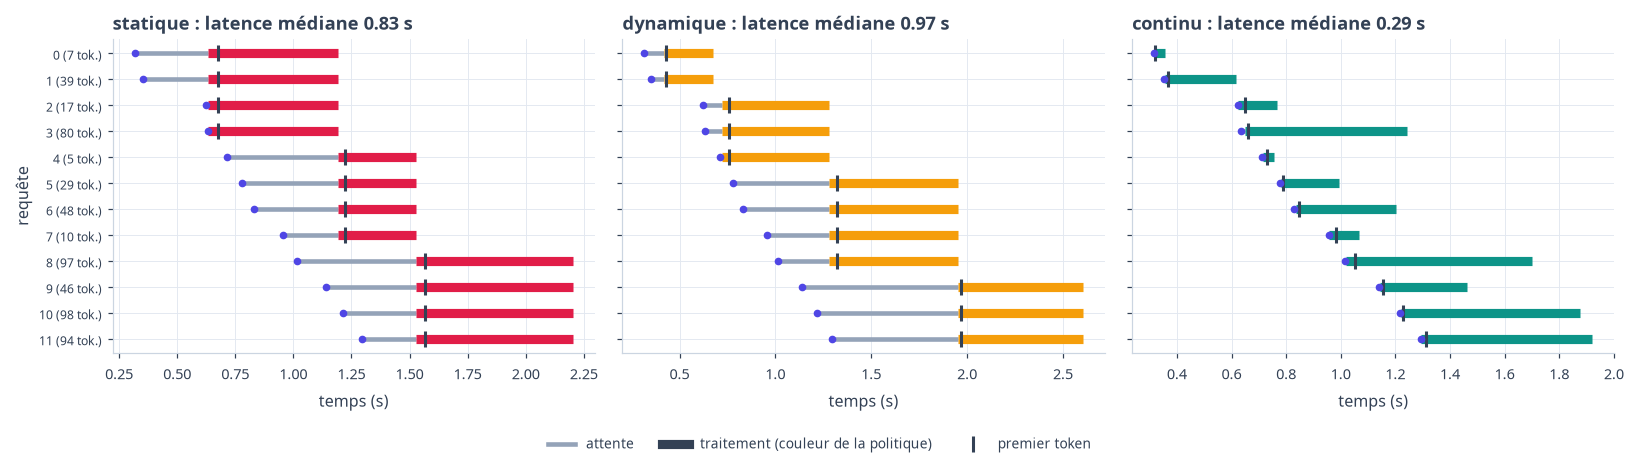

In [4]:
w12 = inf.make_workload(12, rate=12, seed=4, out_median=40, out_sigma=0.9)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, pol in zip(axes, ["static", "dynamic", "continuous"]):
    res = inf.simulate_batching(w12, pol, max_batch=4, window=0.1, cost=cost)
    name, c = POL[pol]
    for i, r in res.iterrows():
        ax.plot([r.arrivee, r.debut], [i, i], color=GRAY, lw=3, solid_capstyle="butt")
        ax.plot([r.debut, r.fin], [i, i], color=c, lw=6, solid_capstyle="butt")
        ax.plot(r.premier_token, i, "|", color=SLATE, ms=10, mew=2)
        ax.plot(r.arrivee, i, "o", color=INDIGO, ms=4)
    ax.set_title(f"{name} : latence médiane {res['latence'].median():.2f} s")
    ax.set_xlabel("temps (s)"); ax.invert_yaxis() if pol == "static" else None
axes[0].set_ylabel("requête")
axes[0].set_yticks(range(12), [f"{i} ({o} tok.)" for i, o in enumerate(w12["sortie"])], fontsize=8)
handles = [plt.Line2D([], [], color=GRAY, lw=3, label="attente"), plt.Line2D([], [], color=SLATE, lw=6, label="traitement (couleur de la politique)"),
           plt.Line2D([], [], color=SLATE, marker="|", ls="", ms=10, mew=2, label="premier token")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

En statique, les premières requêtes attendent que le lot se remplisse ; en dynamique, la
fenêtre limite cette attente ; dans les deux cas, les réponses courtes restent bloquées
jusqu'à la fin de la plus longue de leur lot (barres colorées longues pour quelques tokens).
En continu, chaque requête démarre dès qu'une place se libère et sort dès qu'elle a fini.

**Latence contre débit.** On fait maintenant varier le taux d'arrivée (400 requêtes par
point, lots d'au plus 16) et l'on trace la latence médiane et le p90 en fonction du débit
effectivement obtenu.

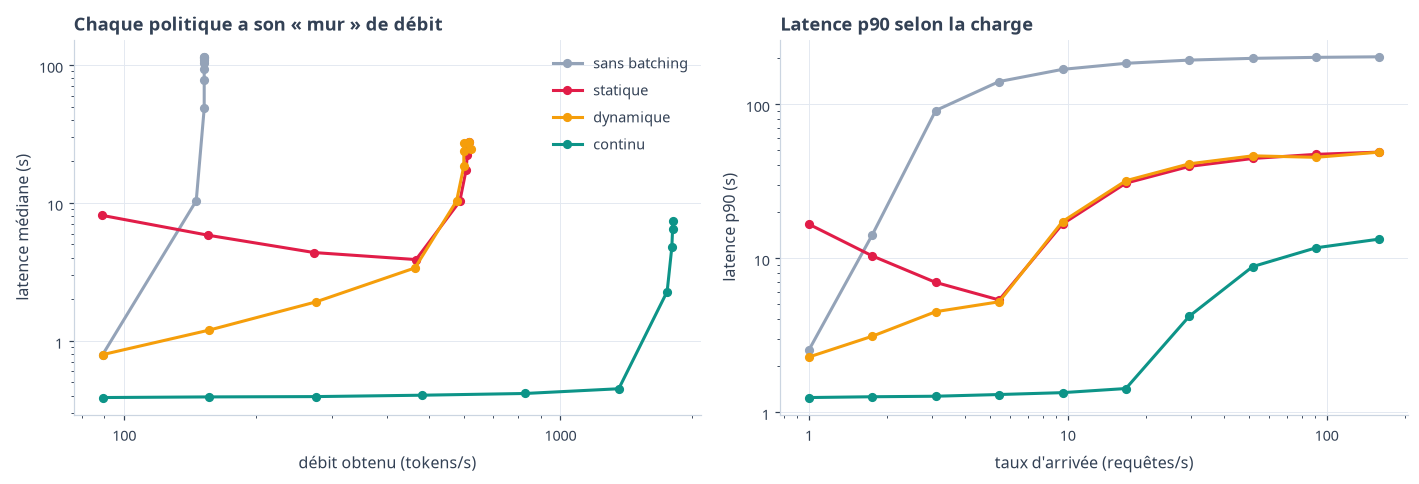

politique,débit (tokens/s)
continu,"1,809"
dynamique,623
sans batching,153
statique,616


In [5]:
rates = np.geomspace(1, 160, 10)
rows = []
for pol in ["none", "static", "dynamic", "continuous"]:
    for lam in rates:
        w = inf.make_workload(400, rate=lam, seed=1)
        res = inf.simulate_batching(w, pol, max_batch=16, window=0.1, cost=cost)
        s = inf.batching_summary(res)
        rows.append(dict(politique=pol, taux=lam, **s))
curves = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for pol, g in curves.groupby("politique", sort=False):
    name, c = POL[pol]
    axes[0].plot(g["débit (tokens/s)"], g["latence p50 (s)"], "o-", color=c, label=name, ms=5)
    axes[1].plot(g["taux"], g["latence p90 (s)"], "o-", color=c, label=name, ms=5)
for ax in axes:
    ax.set_yscale("log"); plain_log_axis(ax, "y")
axes[0].set_xscale("log"); plain_log_axis(axes[0], "x")
axes[0].set_xlabel("débit obtenu (tokens/s)"); axes[0].set_ylabel("latence médiane (s)")
axes[0].set_title("Chaque politique a son « mur » de débit"); axes[0].legend()
axes[1].set_xscale("log"); plain_log_axis(axes[1], "x")
axes[1].set_xlabel("taux d'arrivée (requêtes/s)"); axes[1].set_ylabel("latence p90 (s)")
axes[1].set_title("Latence p90 selon la charge")
plt.tight_layout(); plt.show()
best = curves.loc[curves.groupby("politique")["débit (tokens/s)"].idxmax(), ["politique", "débit (tokens/s)"]]
best.assign(politique=best["politique"].map(lambda p: POL[p][0])).style.format({"débit (tokens/s)": "{:,.0f}"}).hide(axis="index")

Lecture :

- **sans batching**, le serveur sature vite : au-delà de quelques requêtes par seconde, la
  file s'allonge sans fin et la latence explose ;
- le batching **statique** est absurde à faible charge (on attend que le lot se remplisse,
  d'où une latence élevée quand les requêtes sont rares), puis raisonnable à forte charge ;
- le **dynamique** corrige la faible charge grâce à sa fenêtre, mais garde le défaut des
  lots naïfs (attendre la plus longue réponse du lot) ;
- le **continu** domine partout : latence plus faible à charge égale et débit maximal le
  plus élevé, parce qu'aucune place du lot n'est gaspillée par une requête déjà finie.
  C'est la politique par défaut des serveurs modernes (vLLM, TGI, TensorRT-LLM), et elle
  se marie avec PagedAttention (cours 3) qui fournit la mémoire de cache à la demande.

> **À retenir.** Statique : simple mais attend les retardataires ; dynamique : borne
> l'attente ; continu : recompose le lot à chaque pas, et repousse le mur de débit sans
> sacrifier la latence. Le batching est le levier de coût le plus simple et le plus fort.

## 4. Dissocier prefill et decode (section *Decoupling prefill and decode*)

Prefill (limité par le calcul) et decode (limité par la mémoire) se gênent quand ils
partagent un GPU : dans un batching continu, l'arrivée d'une nouvelle requête insère son
prefill dans un pas de decode, et **tous** les utilisateurs en cours voient leur token
suivant retardé. Avec de longs prompts, ces à-coups dégradent le TPOT (ou plutôt l'écart
maximal entre deux tokens, ITL).

**DistServe** (Zhong et al., 2024) et *Inference Without Interference* (Hu et al., 2024)
proposent de placer prefill et decode sur des **instances différentes** et de transférer
le cache KV de l'une à l'autre (rapide avec NVLink). Simulation à budget égal, deux GPU :
deux répliques « tout-en-un » contre un GPU de prefill et un GPU de decode, avec des
prompts longs (1 500 tokens en moyenne).

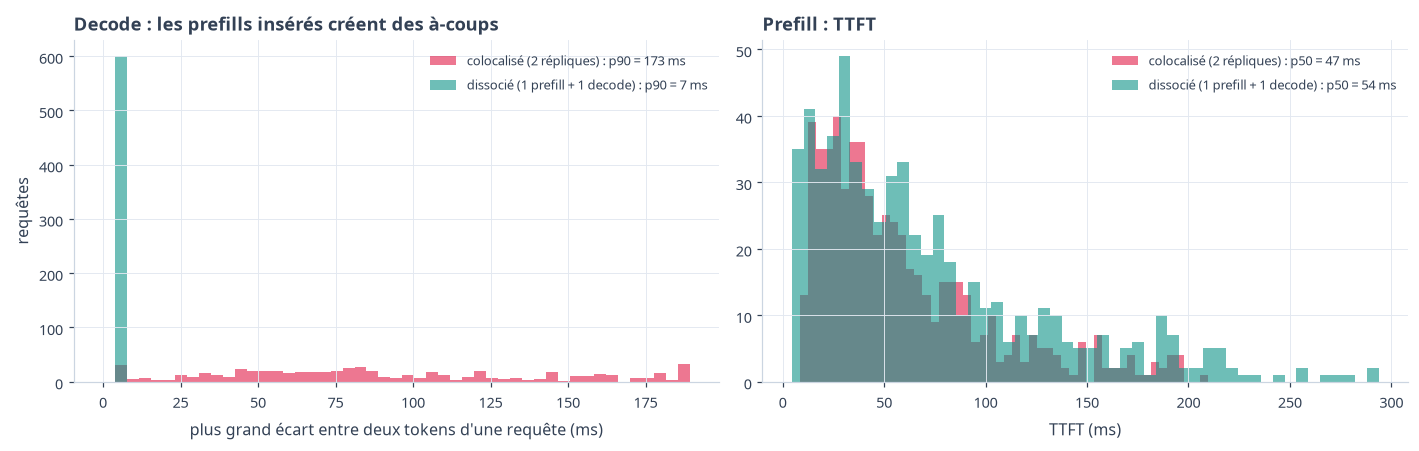

In [6]:
wl = inf.make_workload(600, rate=8, seed=2, prompt_mean=1500, out_median=120, out_sigma=0.6)
sim = inf.simulate_colocated_vs_disaggregated(wl, cost, max_batch=32, transfer_s=0.003)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for (name, (ttft, itl)), c in zip(sim.items(), [ROSE, TEAL]):
    axes[0].hist(itl * 1e3, bins=np.linspace(0, max(np.percentile(np.concatenate([v[1] for v in sim.values()]) * 1e3, 99.5), 1), 50),
                 color=c, alpha=0.6, label=f"{name} : p90 = {np.percentile(itl, 90) * 1e3:.0f} ms")
    axes[1].hist(ttft * 1e3, bins=50, color=c, alpha=0.6, label=f"{name} : p50 = {np.median(ttft) * 1e3:.0f} ms")
axes[0].set_xlabel("plus grand écart entre deux tokens d'une requête (ms)"); axes[0].set_ylabel("requêtes")
axes[0].set_title("Decode : les prefills insérés créent des à-coups"); axes[0].legend(fontsize=8.5)
axes[1].set_xlabel("TTFT (ms)"); axes[1].set_title("Prefill : TTFT"); axes[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Avec les GPU colocalisés, chaque arrivée bloque les decodes en cours le temps d'un prefill
de 1 500 tokens : l'écart maximal entre deux tokens est plusieurs fois le pas de decode
normal. Dissocié, le GPU de decode ne fait que du decode, et l'écart reste égal au pas.
Le TTFT, lui, dépend de la charge du GPU de prefill : ici il reste comparable, mais si les
prompts s'allongent ou si le trafic augmente, il faut **plus d'instances de prefill**.

Le livre donne des ordres de grandeur pour le rapport entre instances de prefill et de
decode : de 2:1 à 4:1 pour des entrées longues avec priorité au TTFT, de 1:2 à 1:1 pour des
entrées courtes avec priorité au TPOT. Un calcul d'équilibre simple : chaque type
d'instance doit suivre le flux de travail qui lui revient.

In [7]:
def pd_ratio(prompt_len, out_len, rate, cost, batch_decode=32):
    load_prefill = rate * cost.prefill(prompt_len)  # secondes de prefill par seconde
    # une instance de decode sert batch_decode séquences : un pas pour batch_decode tokens
    load_decode = rate * out_len * cost.decode(batch_decode) / batch_decode
    return load_prefill, load_decode


rows = []
for P, O in [(4000, 200), (2000, 300), (500, 500), (200, 800)]:
    lp, ld = pd_ratio(P, O, rate=10, cost=cost)
    rows.append({"prompt": P, "sortie": O, "instances prefill (charge)": lp, "instances decode (charge)": ld,
                 "rapport prefill : decode": f"{lp / ld:.1f} : 1"})
pd.DataFrame(rows).style.format({"instances prefill (charge)": "{:.2f}", "instances decode (charge)": "{:.2f}"}).hide(axis="index")

prompt,sortie,instances prefill (charge),instances decode (charge),rapport prefill : decode
4000,200,1.22,0.41,3.0 : 1
2000,300,0.62,0.62,1.0 : 1
500,500,0.16,1.03,0.2 : 1
200,800,0.07,1.65,0.0 : 1


Avec les coûts mesurés de notre petit modèle, les longs prompts demandent plus de capacité
de prefill que de decode, et l'inverse pour les réponses longues : on retrouve la logique
des rapports cités par le livre (les valeurs exactes dépendent du modèle, du matériel et
des objectifs de latence).

> **À retenir.** Séparer prefill et decode supprime leurs interférences (TPOT stable) et
> permet de dimensionner chaque phase selon la charge ; le prix est le transfert du cache
> KV entre instances, négligeable avec des liaisons rapides.

## 5. Cache de prompt (section *Prompt caching*)

Beaucoup de prompts partagent un **préfixe** : le prompt système, un long document, l'historique
d'une conversation. Le **cache de prompt** (ou cache de contexte, de préfixe ; Gim et al.,
2023) garde le cache KV de ce préfixe pour le réutiliser : seule la partie nouvelle est
préremplie. C'est le cache KV du cours 3, mais partagé **entre requêtes**.

**Mesure.** Un prompt système synthétique d'environ 1 500 tokens (documentation fictive),
suivi de questions courtes. On compare le TTFT avec un prefill complet et avec la
réutilisation du cache du préfixe (calculé une fois, puis tronqué après chaque question).

prompt système : 1418 tokens


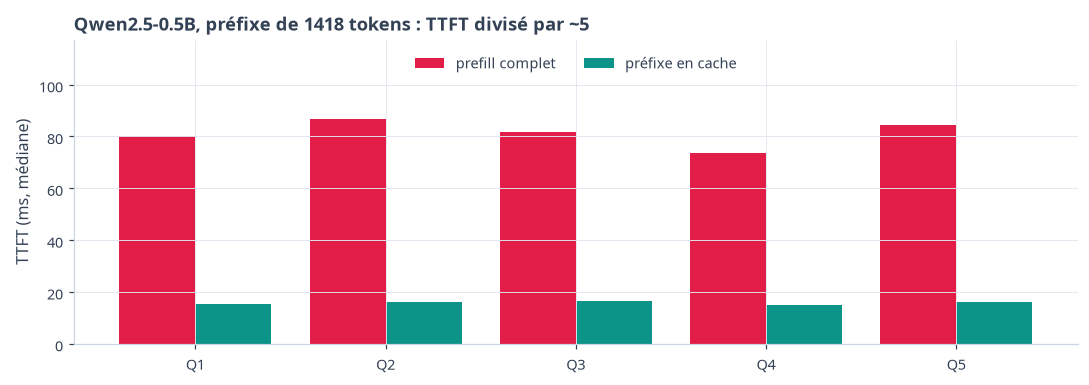

premier token identique dans tous les cas : True


In [8]:
system = ("You are the support assistant of a cloud company. Reference documentation follows.\n"
          + (inf.EVAL_TEXT + "\n" + inf.CALIB_TEXT + "\n" + inf.CODE_SNIPPET + "\n") * 3)
questions = ["What limits the speed of generation?", "How does batching reduce cost?",
             "What does the function moving_average return?", "Why are output tokens expensive?",
             "Give one benefit of caching."]
sys_ids = tok(system, return_tensors="pt")["input_ids"].cuda()
print(f"prompt système : {sys_ids.shape[1]} tokens")


def prompt_cache_bench():
    rows = []
    with torch.no_grad():
        prefix_cache = model(sys_ids, use_cache=True, logits_to_keep=1).past_key_values
        n_sys = sys_ids.shape[1]
        for q in questions:
            q_ids = tok(" " + q, return_tensors="pt")["input_ids"].cuda()
            full = torch.cat([sys_ids, q_ids], 1)

            def no_cache():
                return model(full, use_cache=True, logits_to_keep=1).logits[0, -1].argmax().item()

            def with_cache():
                t = model(q_ids, cache=prefix_cache, use_cache=True, logits_to_keep=1).logits[0, -1].argmax().item()
                inf._crop_to(prefix_cache, n_sys)
                return t

            a, b = no_cache(), with_cache()
            rows.append({"question": q[:40], "tokens nouveaux": q_ids.shape[1],
                         "TTFT sans cache (ms)": inf.time_fn(no_cache, repeats=5)["median"] * 1e3,
                         "TTFT avec cache (ms)": inf.time_fn(with_cache, repeats=5)["median"] * 1e3,
                         "même 1er token": a == b})
    return pd.DataFrame(rows)


pc = inf.retry_oom(prompt_cache_bench)
fig, ax = plt.subplots(figsize=(10, 3.6))
xx = np.arange(len(pc))
ax.bar(xx - 0.2, pc["TTFT sans cache (ms)"], 0.4, color=ROSE, label="prefill complet")
ax.bar(xx + 0.2, pc["TTFT avec cache (ms)"], 0.4, color=TEAL, label="préfixe en cache")
ax.set_xticks(xx, [f"Q{i + 1}" for i in xx]); ax.set_ylabel("TTFT (ms, médiane)")
gain = pc["TTFT sans cache (ms)"].median() / pc["TTFT avec cache (ms)"].median()
ax.set_title(f"Qwen2.5-0.5B, préfixe de {sys_ids.shape[1]} tokens : TTFT divisé par ~{gain:.0f}")
ax.set_ylim(0, pc["TTFT sans cache (ms)"].max() * 1.35); ax.legend(loc="upper center", ncol=2)
plt.tight_layout(); plt.show()
print("premier token identique dans tous les cas :", bool(pc["même 1er token"].all()))

Le TTFT tombe à celui d'un tout petit prefill (quelques tokens de question), avec le même
premier token. Le gain croît avec la longueur du préfixe ; il a un coût **mémoire** (le
cache du préfixe occupe la mémoire GPU tant qu'on le garde) et un coût d'ingénierie si on
l'implémente soi-même.

**Côté facture.** Les fournisseurs répercutent l'économie : au moment où le livre est
écrit, Gemini facture les tokens en cache 75 % moins cher (plus un loyer de stockage) et
Anthropic annonce jusqu'à 90 % d'économie et 75 % de latence en moins (tableau 9-3). Avec
un prompt système de 1 000 tokens et un million d'appels par jour, on évite de
repréremplir un milliard de tokens par jour. Calcul avec une tarification de ce type
(écriture du cache majorée de 25 %, lecture à 10 % du prix ; prix hypothétiques de 3 \$ par
million de tokens d'entrée et 15 \$ en sortie) :

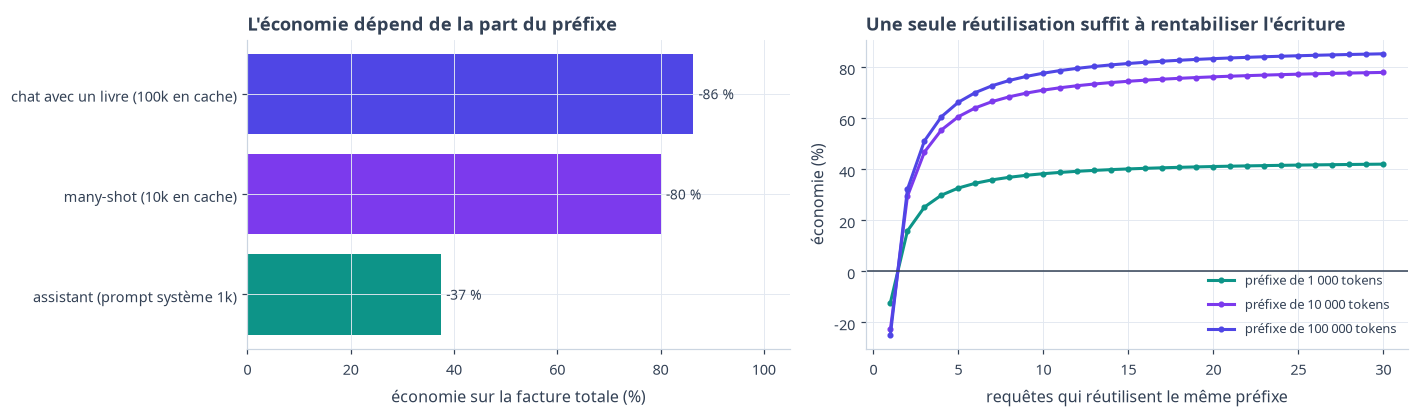

scénario,requêtes,sans cache ($),avec cache ($),économie
chat avec un livre (100k en cache),50,15.23,2.08,86%
many-shot (10k en cache),100,3.33,0.66,80%
assistant (prompt système 1k),10000,72.00,45.00,37%


In [9]:
scen = {"chat avec un livre (100k en cache)": (100_000, 50, 300, 50),
        "many-shot (10k en cache)": (10_000, 100, 200, 100),
        "assistant (prompt système 1k)": (1_000, 150, 250, 10_000)}
rows = []
for name, (cached, fresh, out, n_req) in scen.items():
    r = inf.prompt_cache_savings(n_req, cached, fresh, out, price_in=3.0, price_out=15.0)
    rows.append({"scénario": name, "requêtes": n_req, **r})
sav = pd.DataFrame(rows)
n_req = np.arange(1, 31)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
ax = axes[0]
ax.barh(sav["scénario"], sav["économie"] * 100, color=[INDIGO, VIOLET, TEAL])
for i, v in enumerate(sav["économie"] * 100):
    ax.text(v + 1, i, f"-{v:.0f} %", va="center", fontsize=9)
ax.set_xlim(0, 105); ax.set_xlabel("économie sur la facture totale (%)"); ax.invert_yaxis()
ax.set_title("L'économie dépend de la part du préfixe")
ax = axes[1]
for cached, c in [(1_000, TEAL), (10_000, VIOLET), (100_000, INDIGO)]:
    e = [inf.prompt_cache_savings(n, cached, 50, 200, 3.0, 15.0)["économie"] for n in n_req]
    ax.plot(n_req, np.array(e) * 100, "o-", ms=3, color=c, label=f"préfixe de {cached:,} tokens".replace(",", " "))
ax.axhline(0, color=SLATE, lw=1)
ax.set_xlabel("requêtes qui réutilisent le même préfixe"); ax.set_ylabel("économie (%)")
ax.set_title("Une seule réutilisation suffit à rentabiliser l'écriture"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
sav.style.format({"sans cache ($)": "{:.2f}", "avec cache ($)": "{:.2f}", "économie": "{:.0%}"}).hide(axis="index")

L'économie est d'autant plus forte que le préfixe pèse lourd dans la requête : énorme pour
« discuter avec un livre », plus modeste quand les tokens de sortie dominent la facture.
Avec une majoration d'écriture de 25 % et une lecture à 10 %, le cache est rentable dès la
**deuxième** requête qui réutilise le préfixe (à condition qu'elle arrive avant
l'expiration du cache, souvent quelques minutes).

> **À retenir.** Le cache de prompt réutilise le cache KV d'un préfixe commun entre
> requêtes : TTFT et coût d'entrée chutent pour les longs prompts système, documents et
> conversations. Placez la partie **stable** du prompt au début.

## 6. Parallélisme (section *Parallelism*)

**Répliques.** La stratégie la plus simple : plusieurs copies du modèle, chacune servant
une partie des requêtes (en entraînement, on parle de parallélisme de données). Plus de
répliques, plus de requêtes simultanées... et plus de puces. Avec des modèles de tailles
différentes et des GPU de mémoires différentes, le placement devient un problème de
**rangement** (*bin packing*). Exemple dans l'esprit du livre : modèles de 8, 13, 34 et
70 milliards de paramètres en 8 bits (1 Go par milliard), plus 20 % de marge pour le cache
KV, sur des GPU de 24, 40, 48 et 80 Go. Heuristique gloutonne « premier qui convient,
par taille décroissante » :

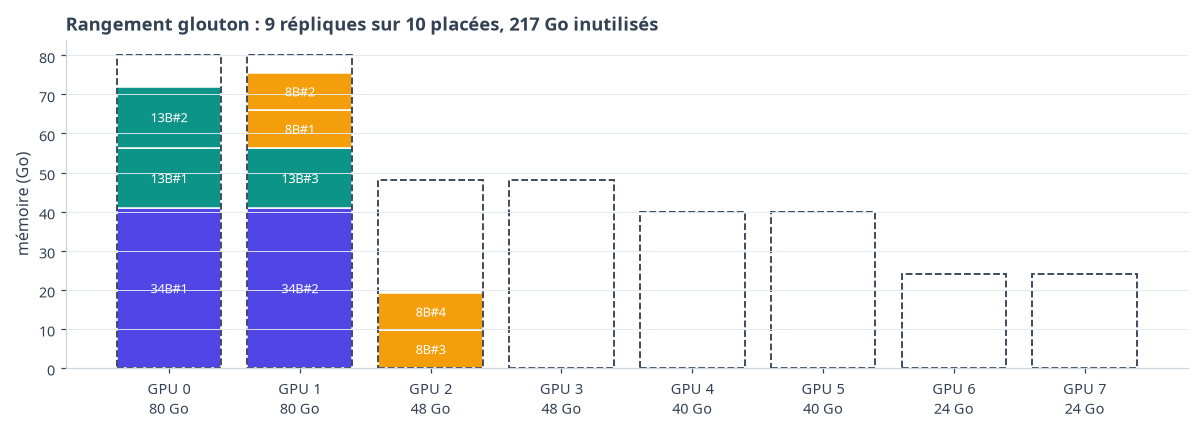

non placés : ['70B#1']


In [10]:
want = {"70B": 1, "34B": 2, "13B": 3, "8B": 4}
items = {f"{m}#{i + 1}": int(m[:-1]) * 1.2 for m, k in want.items() for i in range(k)}
gpus = [80, 80, 48, 48, 40, 40, 24, 24]
placement, free = inf.first_fit_decreasing(items, gpus)
fig, ax = plt.subplots(figsize=(11, 4))
cols = {"70B": VIOLET, "34B": INDIGO, "13B": TEAL, "8B": AMBER}
bottoms = np.zeros(len(gpus))
for name, g in placement.items():
    if g is None:
        continue
    size = items[name]
    ax.bar(g, size, bottom=bottoms[g], color=cols[name.split("#")[0]], edgecolor="white")
    ax.text(g, bottoms[g] + size / 2, name, ha="center", va="center", color="white", fontsize=8.5)
    bottoms[g] += size
ax.bar(range(len(gpus)), gpus, color="none", edgecolor=SLATE, lw=1.2, ls="--")
ax.set_xticks(range(len(gpus)), [f"GPU {i}\n{c} Go" for i, c in enumerate(gpus)])
ax.set_ylabel("mémoire (Go)"); ax.grid(axis="x", visible=False)
ax.set_title(f"Rangement glouton : {sum(v is not None for v in placement.values())} répliques sur {len(items)} placées,"
             f" {sum(free):.0f} Go inutilisés")
plt.tight_layout(); plt.show()
print("non placés :", [k for k, v in placement.items() if v is None] or "aucun")

Première leçon : le 70B ne tient sur **aucun** GPU avec sa marge (84 Go) ; il faudra le
découper sur plusieurs puces (parallélisme de modèle, ci-dessous). Ensuite, le glouton est
rapide mais pas optimal, et la vraie question est souvent inverse : avec un
nombre fixe de puces, combien de répliques de chaque modèle créer pour maximiser le
goodput ? (Trois 13B sur un GPU de 40 Go ne tiennent pas avec leur cache, d'où la question
du livre : vaut-il mieux y mettre un 34B ?)

**Parallélisme de tenseur** (*intra-operator*). Quand un modèle ne tient pas sur une puce,
on découpe **chaque** opérateur. Pour $Y = XW$, on peut couper $W$ par **colonnes** : chaque
GPU calcule un bloc de colonnes de $Y$, qu'on concatène (*all-gather*) ; ou par **lignes**
(et $X$ par colonnes) : chaque GPU calcule une somme partielle, qu'on additionne
(*all-reduce*). Megatron-LM enchaîne les deux dans chaque MLP pour une seule communication.

découpe en colonnes exacte : True | en lignes exacte : True


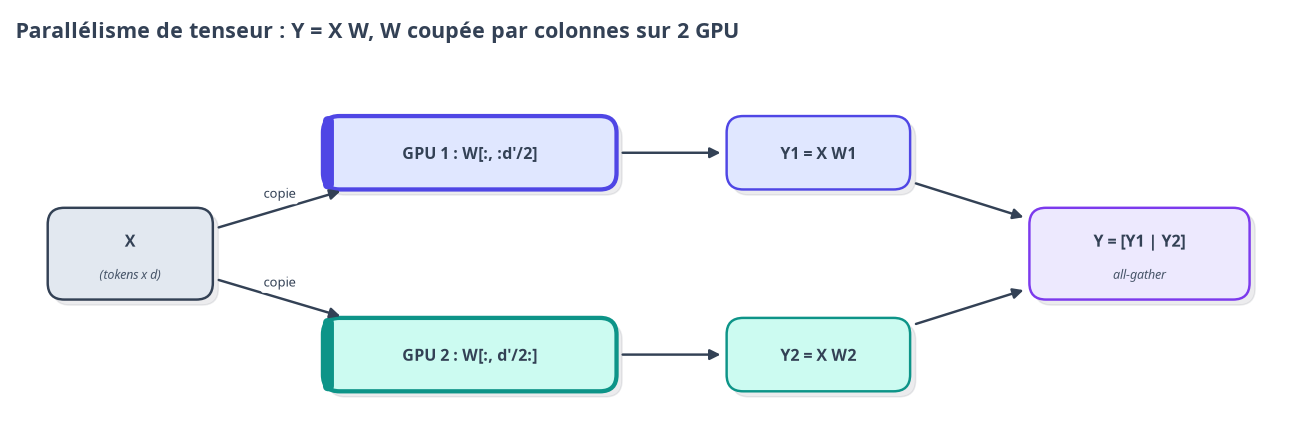

In [11]:
X_ = rng.normal(size=(4, 8)); W_ = rng.normal(size=(8, 6))
Yc, parts_c = inf.tensor_parallel_matmul(X_, W_, 2, "column")
Yr, parts_r = inf.tensor_parallel_matmul(X_, W_, 2, "row")
print("découpe en colonnes exacte :", np.allclose(Yc, X_ @ W_), "| en lignes exacte :", np.allclose(Yr, X_ @ W_))

d = Diagram(14, 4.0, title="Parallélisme de tenseur : Y = X W, W coupée par colonnes sur 2 GPU")
d.box("x", 1.3, 1.9, "X", sub="(tokens x d)", color=SLATE, w=1.8, h=1.0)
d.box("w1", 5.0, 3.0, "GPU 1 : W[:, :d'/2]", color=INDIGO, kind="model", w=3.2, h=0.8)
d.box("w2", 5.0, 0.8, "GPU 2 : W[:, d'/2:]", color=TEAL, kind="model", w=3.2, h=0.8)
d.box("y1", 8.8, 3.0, "Y1 = X W1", color=INDIGO, w=2.0, h=0.8)
d.box("y2", 8.8, 0.8, "Y2 = X W2", color=TEAL, w=2.0, h=0.8)
d.box("y", 12.3, 1.9, "Y = [Y1 | Y2]", sub="all-gather", color=VIOLET, w=2.4, h=1.0)
d.arrow("x", "w1", "copie"); d.arrow("x", "w2", "copie"); d.arrow("w1", "y1"); d.arrow("w2", "y2")
d.arrow("y1", "y"); d.arrow("y2", "y")
d.show()

Double bénéfice : servir un modèle trop gros pour une puce, et **réduire la latence**,
car chaque GPU ne lit que $1/p$ des poids à chaque pas de decode. Mais il faut communiquer
(deux *all-reduce* par bloc de transformer) : estimons la latence d'un token de Llama
3-70B (fp16, 140 Go) selon le degré $p$ de parallélisme, avec un coût fixe par
communication de 10 µs sur NVLink et 40 µs sur PCIe.

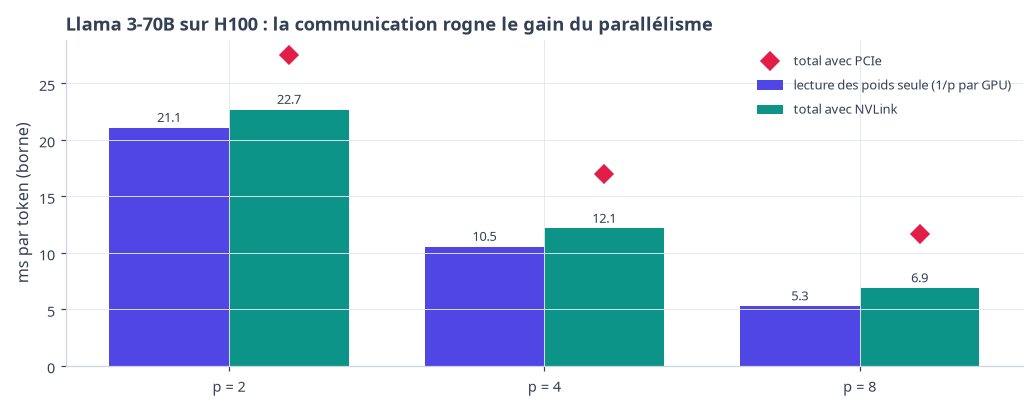

In [12]:
cfg70 = KNOWN_CONFIGS["Llama 3-70B"]
w_bytes = count_params_config(cfg70) * 2
ps = np.array([2, 4, 8])
read = w_bytes / ps / inf.ACCELERATORS["H100 SXM"]["bw"]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
wbar = 0.38
ax.bar(np.arange(3) - wbar / 2, read * 1e3, wbar, color=INDIGO, label="lecture des poids seule (1/p par GPU)")
tot_nv = (read + 2 * cfg70.n_layers * 10e-6) * 1e3
tot_pc = (read + 2 * cfg70.n_layers * 40e-6) * 1e3
ax.bar(np.arange(3) + wbar / 2, tot_nv, wbar, color=TEAL, label="total avec NVLink")
ax.plot(np.arange(3) + wbar / 2, tot_pc, "D", color=ROSE, ms=8, label="total avec PCIe")
for i in range(3):
    ax.text(i - wbar / 2, read[i] * 1e3 + 0.5, f"{read[i] * 1e3:.1f}", ha="center", fontsize=8.5)
    ax.text(i + wbar / 2, tot_nv[i] + 0.5, f"{tot_nv[i]:.1f}", ha="center", fontsize=8.5)
ax.set_xticks(range(3), [f"p = {p}" for p in ps]); ax.set_ylabel("ms par token (borne)")
ax.set_title("Llama 3-70B sur H100 : la communication rogne le gain du parallélisme")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Doubler $p$ divise par deux le temps de lecture des poids, mais le coût de communication
(160 *all-reduce* par token ici) reste constant : avec $p = 8$ il devient une part notable
de la latence, surtout sans liaison rapide. C'est pourquoi le parallélisme de tenseur reste
à l'intérieur d'un nœud (8 GPU reliés par NVLink).

**Parallélisme de pipeline.** On coupe le modèle en **étages** consécutifs (par exemple
20 couches par GPU), et on découpe le lot en **micro-lots** qui circulent d'étage en étage.
Pendant que l'étage 2 traite le micro-lot 1, l'étage 1 traite le micro-lot 2. Au début et à
la fin, des étages sont inactifs : la **bulle**, de fraction $\frac{p-1}{m+p-1}$ pour $p$
étages et $m$ micro-lots.

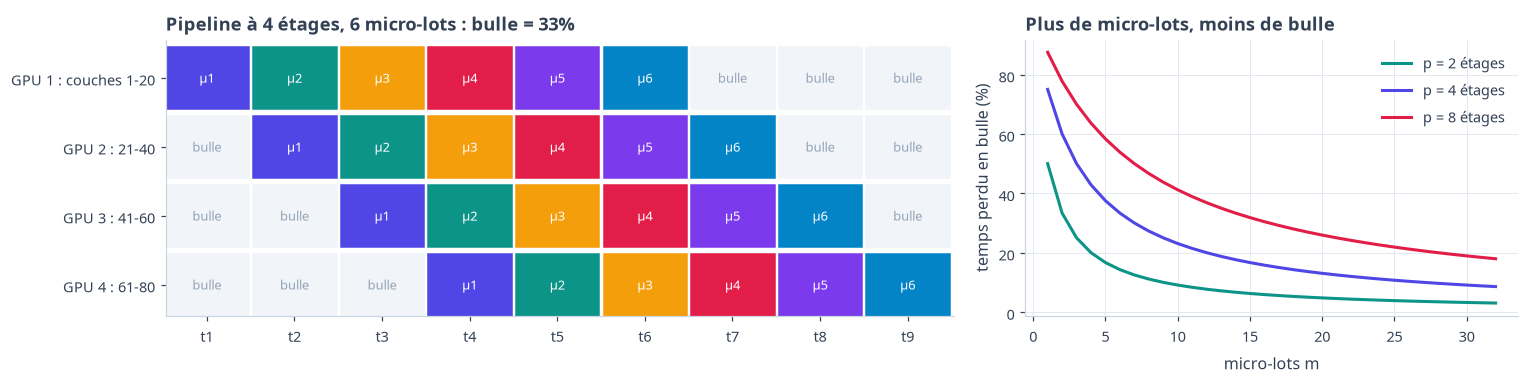

In [13]:
grid = inf.pipeline_schedule(4, 6)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
for s in range(4):
    for t in range(grid.shape[1]):
        mb = grid[s, t]
        ax.add_patch(plt.Rectangle((t, 3 - s), 0.95, 0.9, color=COLORS[mb % 8] if mb >= 0 else "#F1F5F9"))
        ax.text(t + 0.47, 3 - s + 0.45, f"µ{mb + 1}" if mb >= 0 else "bulle", ha="center", va="center",
                color="white" if mb >= 0 else GRAY, fontsize=8.5)
ax.set_xlim(0, grid.shape[1]); ax.set_ylim(0, 4); ax.grid(False)
ax.set_yticks([3.45, 2.45, 1.45, 0.45], ["GPU 1 : couches 1-20", "GPU 2 : 21-40", "GPU 3 : 41-60", "GPU 4 : 61-80"])
ax.set_xticks(np.arange(grid.shape[1]) + 0.47, [f"t{t + 1}" for t in range(grid.shape[1])])
ax.set_title(f"Pipeline à 4 étages, 6 micro-lots : bulle = {inf.pipeline_bubble_fraction(4, 6):.0%}")
ax = axes[1]
ms_ = np.arange(1, 33)
for p, c in [(2, TEAL), (4, INDIGO), (8, ROSE)]:
    ax.plot(ms_, [inf.pipeline_bubble_fraction(p, m) * 100 for m in ms_], color=c, label=f"p = {p} étages")
ax.set_xlabel("micro-lots m"); ax.set_ylabel("temps perdu en bulle (%)"); ax.legend()
ax.set_title("Plus de micro-lots, moins de bulle")
plt.tight_layout(); plt.show()

Le pipeline permet de servir un modèle réparti sur plusieurs machines et augmente le
débit (d'où son usage en entraînement), mais chaque requête traverse tous les étages en
série, avec une communication à chaque frontière : sa **latence** augmente. Pour les
applications sensibles à la latence, on lui préfère les répliques (et le parallélisme de
tenseur à l'intérieur d'un nœud).

**Contexte et séquence.** Deux techniques plus rares, pour les longues entrées : le
parallélisme de **contexte** coupe la séquence elle-même (première moitié du prompt sur la
machine 1, seconde sur la machine 2) ; le parallélisme de **séquence** répartit les
opérateurs (attention sur une machine, MLP sur une autre, dans l'exemple du livre).

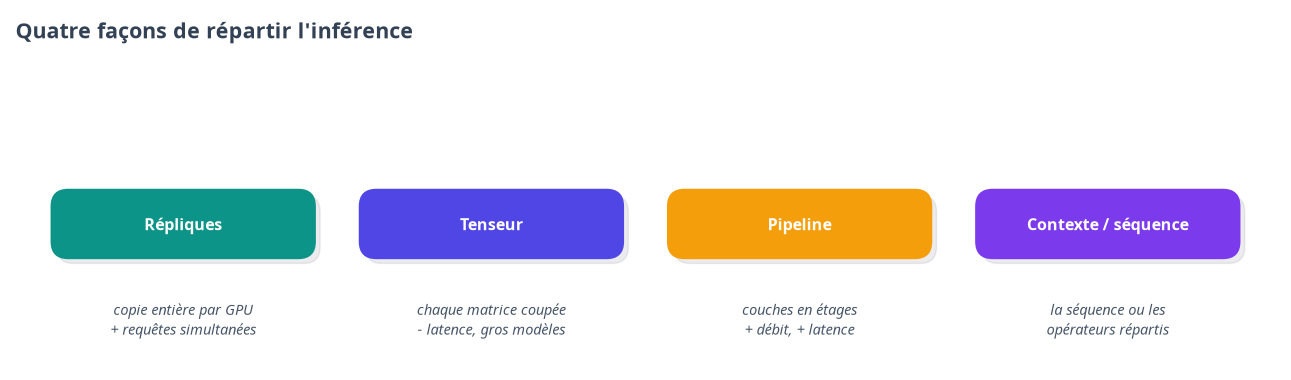

In [14]:
d = Diagram(14, 3.4, title="Quatre façons de répartir l'inférence")
specs = [("rep", "Répliques", "copie entière par GPU\n+ requêtes simultanées", TEAL),
         ("tp", "Tenseur", "chaque matrice coupée\n- latence, gros modèles", INDIGO),
         ("pp", "Pipeline", "couches en étages\n+ débit, + latence", AMBER),
         ("cp", "Contexte / séquence", "la séquence ou les\nopérateurs répartis", VIOLET)]
for i, (k, t, sub, c) in enumerate(specs):
    d.box(k, 1.9 + i * 3.4, 1.6, t, color=c, filled=True, w=2.9, h=0.75)
    d.note(1.9 + i * 3.4, 0.55, sub, fontsize=9.5)
d.show()

> **À retenir.** Répliques : simple, augmente la capacité. Tenseur : réduit la latence et
> permet les gros modèles, limité par la communication. Pipeline : augmente le débit au prix
> de la latence. Le livre retient comme techniques les plus rentables, tous usages
> confondus : quantification, parallélisme de tenseur, répliques et optimisation de
> l'attention.

In [15]:
llm.free_gpu()
del model

## Synthèse

- Le service est une file d'attente : le coût d'un pas de decode, $a_0 + a_1 b$ avec
  $a_0 \gg a_1$, rend le **batching** très rentable ; le batching **continu** recompose le
  lot à chaque pas et domine les politiques statique et dynamique, en latence comme en débit.
- **Dissocier prefill et decode** supprime leurs interférences (TPOT stable) et permet de
  dimensionner chaque phase.
- Le **cache de prompt** réutilise le cache KV d'un préfixe commun : TTFT et coût d'entrée
  chutent dès la deuxième réutilisation.
- **Parallélisme** : répliques (capacité), tenseur (latence, gros modèles), pipeline
  (débit), contexte et séquence (longues entrées).

**Liens.** Cours 1 : métriques (TTFT, TPOT, goodput) que ces techniques arbitrent ;
cours 3 : PagedAttention, indispensable au batching continu ; chapitre 10 : intégration de
ces briques dans l'architecture d'une application (routage, cache, passerelle).